# Visualização de Dados com Python — versão Polars
UNICEUB - AULA 14

Neste notebook vamos trabalhar com o dataset **supermercado_abc_100k_variado.csv** para praticar:

- leitura de dados com **Polars**
- exploração inicial
- criação de indicadores simples
- visualização com Matplotlib e Seaborn

O objetivo é entender como os gráficos ajudam na análise exploratória de dados (EDA).

> **Diferença para a aula original:** em vez de Pandas, usamos Polars para ler e transformar os dados. Polars não tem `.plot()` embutido, então os gráficos são feitos com Matplotlib/Seaborn a partir dos resultados do Polars.

In [37]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

print("Polars:", pl.__version__)

Polars: 1.35.2


## 1. Leitura do arquivo

No Colab, execute a célula abaixo e selecione o arquivo `supermercado_abc_100k_variado.csv` do seu computador.
(Se preferir, monte o Google Drive e ajuste o caminho.)

In [38]:
import os

arquivo = "supermercado_abc_100k_variado.csv"

if not os.path.exists(arquivo):
    from google.colab import files
    files.upload()

df = pl.read_csv(arquivo)

print("Dataset carregado com sucesso!")
print(df.head())

Dataset carregado com sucesso!
shape: (5, 23)
┌────────────┬────────────┬───────────┬───────────┬───┬───────────┬─────────┬──────────┬───────────┐
│ id_item    ┆ id_venda   ┆ data_hora ┆ filial_id ┆ … ┆ custo_tot ┆ imposto ┆ comissao ┆ forma_pag │
│ ---        ┆ ---        ┆ ---       ┆ ---       ┆   ┆ al        ┆ ---     ┆ ---      ┆ amento    │
│ str        ┆ str        ┆ str       ┆ str       ┆   ┆ ---       ┆ f64     ┆ f64      ┆ ---       │
│            ┆            ┆           ┆           ┆   ┆ f64       ┆         ┆          ┆ str       │
╞════════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═════════╪══════════╪═══════════╡
│ ITEM000001 ┆ VENDA01579 ┆ 2025-05-0 ┆ F04       ┆ … ┆ 13.88     ┆ 1.56    ┆ 0.19     ┆ Cartão    │
│            ┆ 6          ┆ 4         ┆           ┆   ┆           ┆         ┆          ┆ Crédito   │
│            ┆            ┆ 07:05:38  ┆           ┆   ┆           ┆         ┆          ┆           │
│ ITEM000002 ┆ VENDA00086 ┆ 2025-12-0 ┆ F05  

## 2. Conhecendo a estrutura dos dados

Antes de criar gráficos, precisamos entender como os dados estão organizados.

In [39]:
print("Quantidade de linhas e colunas:")
print(df.shape)

print("\nNomes das colunas:")
print(df.columns)

print("\nInformações gerais (nome -> tipo):")
print(df.schema)

print("\nValores nulos por coluna:")
print(df.null_count())

Quantidade de linhas e colunas:
(100000, 23)

Nomes das colunas:
['id_item', 'id_venda', 'data_hora', 'filial_id', 'filial', 'cidade', 'estado', 'caixa', 'operador_caixa', 'id_cliente', 'segmento_cliente', 'produto', 'categoria', 'subcategoria', 'marca', 'quantidade', 'preco_unitario', 'desconto_valor', 'valor_liquido', 'custo_total', 'imposto', 'comissao', 'forma_pagamento']

Informações gerais (nome -> tipo):
Schema({'id_item': String, 'id_venda': String, 'data_hora': String, 'filial_id': String, 'filial': String, 'cidade': String, 'estado': String, 'caixa': String, 'operador_caixa': String, 'id_cliente': String, 'segmento_cliente': String, 'produto': String, 'categoria': String, 'subcategoria': String, 'marca': String, 'quantidade': Int64, 'preco_unitario': Float64, 'desconto_valor': Float64, 'valor_liquido': Float64, 'custo_total': Float64, 'imposto': Float64, 'comissao': Float64, 'forma_pagamento': String})

Valores nulos por coluna:
shape: (1, 23)
┌─────────┬──────────┬──────────

## 3. Ajustando tipos de dados

Vamos converter a coluna de data e garantir que as colunas numéricas sejam `Float64`, para que cálculos e gráficos funcionem corretamente.
Em Polars usamos `with_columns` + expressões (`pl.col`). Com `strict=False`, valores inválidos viram `null` (equivale ao `errors="coerce"` do Pandas).

In [40]:
colunas_numericas = [
    "quantidade",
    "preco_unitario",
    "desconto_valor",
    "valor_liquido",
    "custo_total",
    "imposto",
    "comissao",
]

df = df.with_columns(
    pl.col("data_hora").str.to_datetime("%Y-%m-%d %H:%M:%S", strict=False),
    pl.col(colunas_numericas).cast(pl.Float64, strict=False),
)

print(df.schema)

Schema({'id_item': String, 'id_venda': String, 'data_hora': Datetime(time_unit='us', time_zone=None), 'filial_id': String, 'filial': String, 'cidade': String, 'estado': String, 'caixa': String, 'operador_caixa': String, 'id_cliente': String, 'segmento_cliente': String, 'produto': String, 'categoria': String, 'subcategoria': String, 'marca': String, 'quantidade': Float64, 'preco_unitario': Float64, 'desconto_valor': Float64, 'valor_liquido': Float64, 'custo_total': Float64, 'imposto': Float64, 'comissao': Float64, 'forma_pagamento': String})


## 4. Estatísticas básicas

Agora vamos observar algumas estatísticas das colunas numéricas.

In [41]:
print(df.select(colunas_numericas).describe())

shape: (9, 8)
┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ statistic  ┆ quantidade ┆ preco_unit ┆ desconto_ ┆ valor_liq ┆ custo_tot ┆ imposto   ┆ comissao  │
│ ---        ┆ ---        ┆ ario       ┆ valor     ┆ uido      ┆ al        ┆ ---       ┆ ---       │
│ str        ┆ f64        ┆ ---        ┆ ---       ┆ ---       ┆ ---       ┆ f64       ┆ f64       │
│            ┆            ┆ f64        ┆ f64       ┆ f64       ┆ f64       ┆           ┆           │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ count      ┆ 100000.0   ┆ 100000.0   ┆ 100000.0  ┆ 100000.0  ┆ 100000.0  ┆ 100000.0  ┆ 100000.0  │
│ null_count ┆ 0.0        ┆ 0.0        ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ 0.0       │
│ mean       ┆ 2.38128    ┆ 20.446681  ┆ 2.135694  ┆ 46.806803 ┆ 34.311705 ┆ 4.0976457 ┆ 0.5509309 │
│ std        ┆ 1.900742   ┆ 29.530654  ┆ 7.422767  ┆ 95.871403 ┆ 69.918798 ┆ 

## 5. Gráfico 1 – Vendas por categoria

Vamos somar o valor líquido por categoria e criar um gráfico de barras.

In [42]:
vendas_categoria = (
    df.group_by("categoria")
      .agg(pl.col("valor_liquido").sum())
      .sort("categoria")
)

print(vendas_categoria)

shape: (5, 2)
┌─────────────┬───────────────┐
│ categoria   ┆ valor_liquido │
│ ---         ┆ ---           │
│ str         ┆ f64           │
╞═════════════╪═══════════════╡
│ Alimentos   ┆ 1.5936e6      │
│ Bebidas     ┆ 329969.57     │
│ Eletronicos ┆ 2.0692e6      │
│ Higiene     ┆ 338324.19     │
│ Limpeza     ┆ 349586.89     │
└─────────────┴───────────────┘


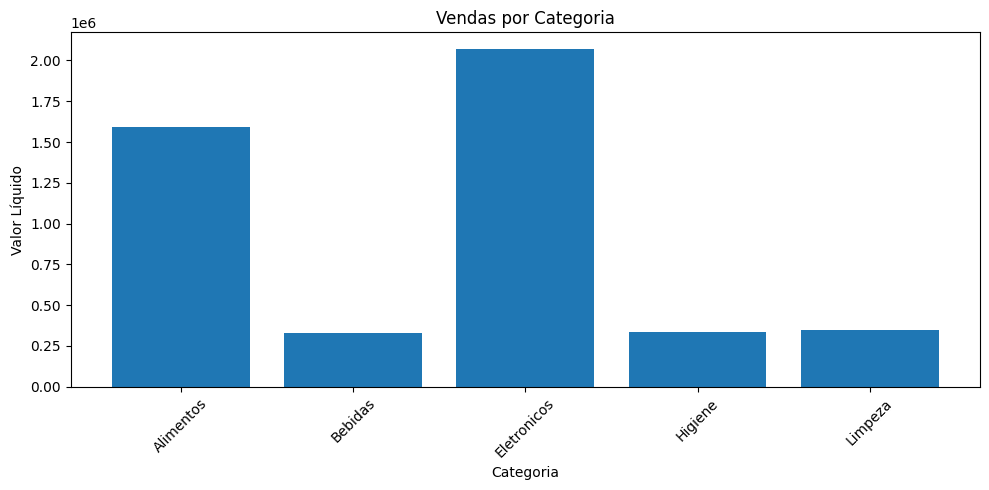

In [43]:
plt.figure(figsize=(10, 5))
plt.bar(vendas_categoria["categoria"], vendas_categoria["valor_liquido"])

plt.title("Vendas por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Valor Líquido")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Gráfico 2 – Vendas por forma de pagamento

Agora vamos comparar as formas de pagamento.

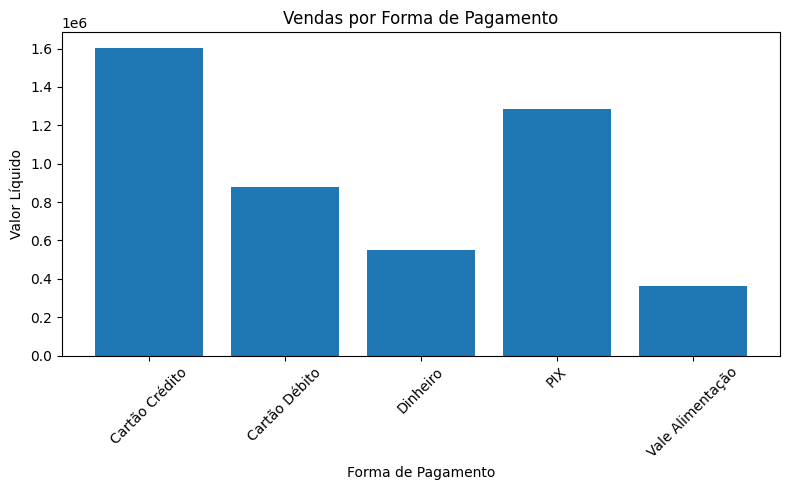

In [44]:
vendas_pagamento = (
    df.group_by("forma_pagamento")
      .agg(pl.col("valor_liquido").sum())
      .sort("forma_pagamento")
)

plt.figure(figsize=(8, 5))
plt.bar(vendas_pagamento["forma_pagamento"], vendas_pagamento["valor_liquido"])

plt.title("Vendas por Forma de Pagamento")
plt.xlabel("Forma de Pagamento")
plt.ylabel("Valor Líquido")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Gráfico 3 – Histograma com Seaborn

O histograma mostra a distribuição dos valores da coluna `valor_liquido`.
Passamos a coluna do Polars convertida para NumPy (`.to_numpy()`) para o Seaborn.

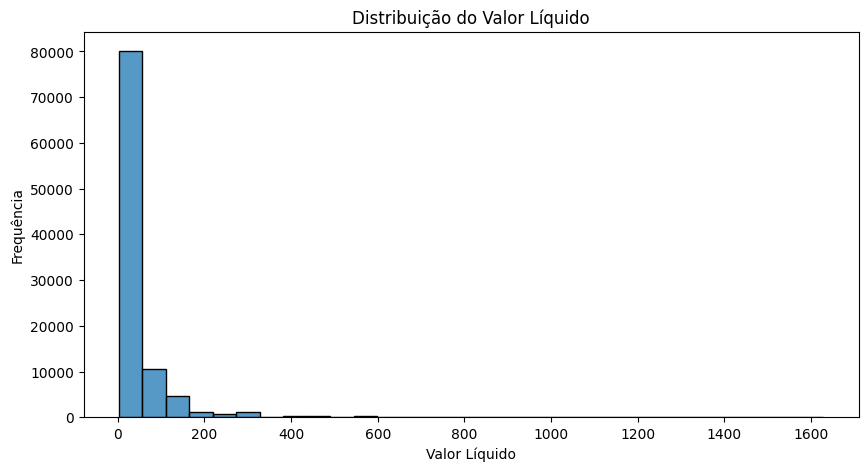

In [45]:
plt.figure(figsize=(10, 5))
sns.histplot(df["valor_liquido"].to_numpy(), bins=30)

plt.title("Distribuição do Valor Líquido")
plt.xlabel("Valor Líquido")
plt.ylabel("Frequência")
plt.show()

## 8. Gráfico 4 – Boxplot

O boxplot ajuda a visualizar dispersão e possíveis valores extremos.

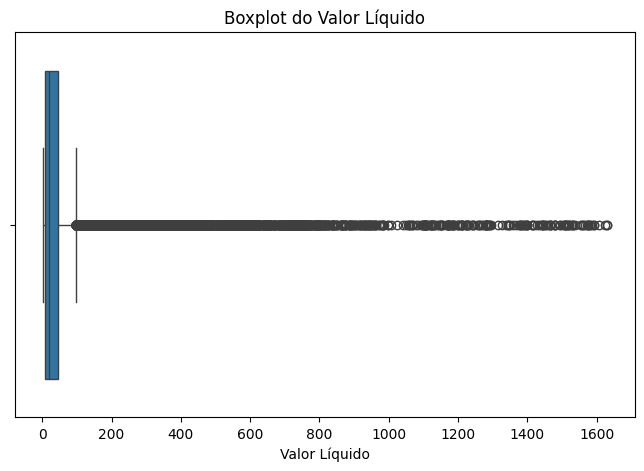

In [46]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["valor_liquido"].to_numpy())

plt.title("Boxplot do Valor Líquido")
plt.xlabel("Valor Líquido")
plt.show()

## 9. Criando coluna de data

Vamos extrair apenas a data para analisar vendas ao longo do tempo.

In [47]:
df = df.with_columns(pl.col("data_hora").dt.date().alias("data"))

print(df.select("data_hora", "data").head())

shape: (5, 2)
┌─────────────────────┬────────────┐
│ data_hora           ┆ data       │
│ ---                 ┆ ---        │
│ datetime[μs]        ┆ date       │
╞═════════════════════╪════════════╡
│ 2025-05-04 07:05:38 ┆ 2025-05-04 │
│ 2025-12-06 04:43:50 ┆ 2025-12-06 │
│ 2025-08-13 06:24:59 ┆ 2025-08-13 │
│ 2025-04-20 09:02:14 ┆ 2025-04-20 │
│ 2026-07-24 09:20:03 ┆ 2026-07-24 │
└─────────────────────┴────────────┘


## 10. Gráfico 5 – Vendas por data

Agora vamos analisar a evolução do valor vendido por dia.
No Polars, `group_by` não garante ordem, então usamos `.sort("data")` para a linha do tempo ficar correta.

In [48]:
vendas_data = (
    df.group_by("data")
      .agg(pl.col("valor_liquido").sum())
      .sort("data")
)

print(vendas_data.head())

shape: (5, 2)
┌────────────┬───────────────┐
│ data       ┆ valor_liquido │
│ ---        ┆ ---           │
│ date       ┆ f64           │
╞════════════╪═══════════════╡
│ 2025-01-01 ┆ 4271.6        │
│ 2025-01-02 ┆ 6753.29       │
│ 2025-01-03 ┆ 6720.9        │
│ 2025-01-04 ┆ 8630.82       │
│ 2025-01-05 ┆ 6245.31       │
└────────────┴───────────────┘


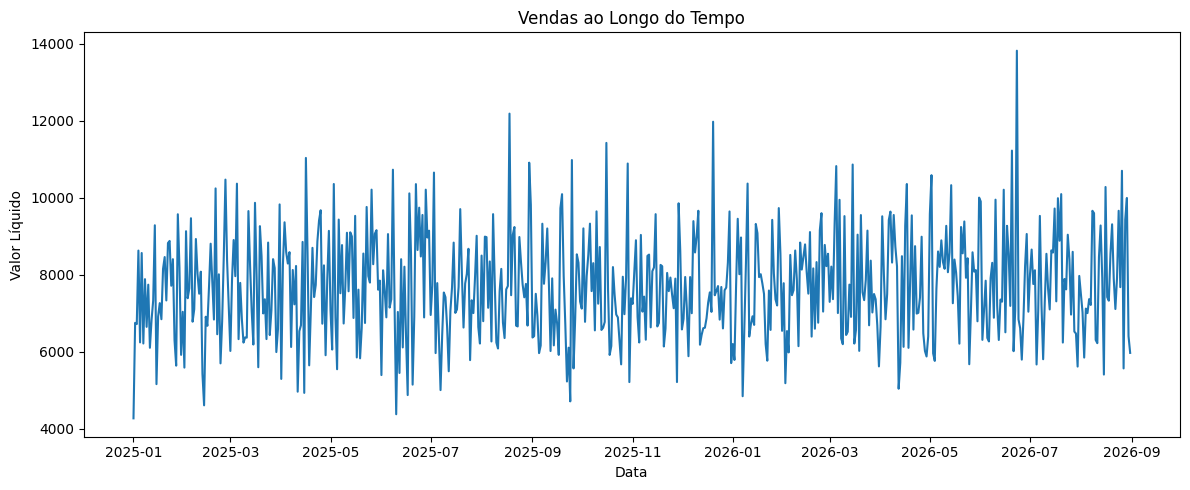

In [49]:
plt.figure(figsize=(12, 5))
plt.plot(vendas_data["data"], vendas_data["valor_liquido"])

plt.title("Vendas ao Longo do Tempo")
plt.xlabel("Data")
plt.ylabel("Valor Líquido")
plt.tight_layout()
plt.show()

## 11. Gráfico 6 – Top 10 produtos mais vendidos

Vamos descobrir quais produtos mais apareceram nas vendas.

In [50]:
top_produtos = df["produto"].value_counts(sort=True).head(10)

print(top_produtos)

shape: (10, 2)
┌──────────────────────┬───────┐
│ produto              ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Arroz 5kg            ┆ 11512 │
│ Feijão 1kg           ┆ 9021  │
│ Refrigerante 2L      ┆ 8056  │
│ Café 500g            ┆ 7552  │
│ Macarrão 500g        ┆ 7462  │
│ Leite 1L             ┆ 6475  │
│ Açúcar 1kg           ┆ 6193  │
│ Detergente 500ml     ┆ 5442  │
│ Papel Higiênico 12un ┆ 4981  │
│ Suco 1L              ┆ 4480  │
└──────────────────────┴───────┘


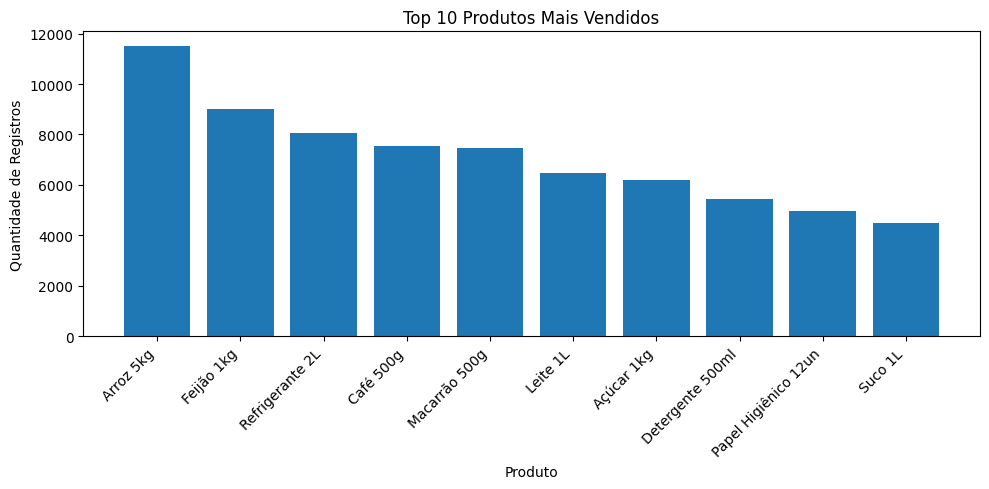

In [51]:
plt.figure(figsize=(10, 5))
plt.bar(top_produtos["produto"], top_produtos["count"])

plt.title("Top 10 Produtos Mais Vendidos")
plt.xlabel("Produto")
plt.ylabel("Quantidade de Registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 12. Gráfico 7 – Valor líquido médio por categoria com Seaborn

Agora vamos analisar a média de valor por categoria.

In [52]:
media_categoria = (
    df.group_by("categoria")
      .agg(pl.col("valor_liquido").mean())
      .sort("categoria")
)

print(media_categoria)

shape: (5, 2)
┌─────────────┬───────────────┐
│ categoria   ┆ valor_liquido │
│ ---         ┆ ---           │
│ str         ┆ f64           │
╞═════════════╪═══════════════╡
│ Alimentos   ┆ 33.051954     │
│ Bebidas     ┆ 19.395143     │
│ Eletronicos ┆ 206.465743    │
│ Higiene     ┆ 31.202083     │
│ Limpeza     ┆ 25.137477     │
└─────────────┴───────────────┘


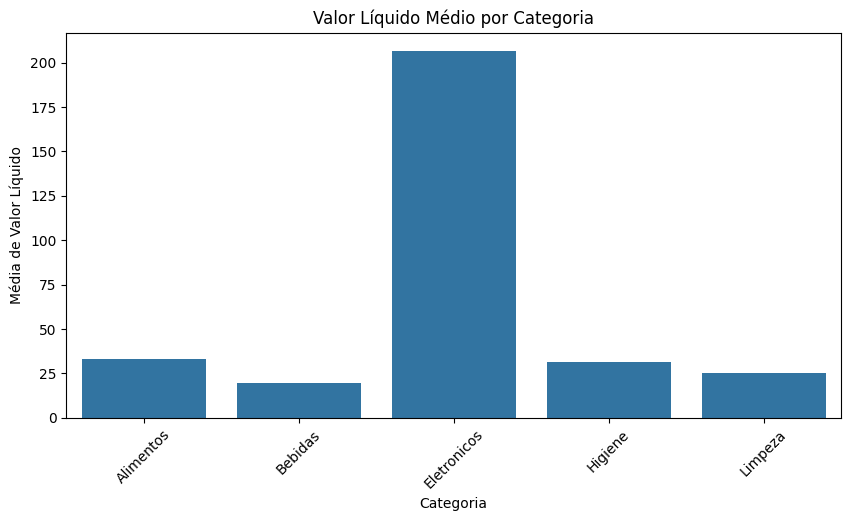

In [53]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x=media_categoria["categoria"].to_list(),
    y=media_categoria["valor_liquido"].to_list(),
)

plt.title("Valor Líquido Médio por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Média de Valor Líquido")
plt.xticks(rotation=45)
plt.show()

## 13. Gráfico 8 – Relação entre preço unitário e valor líquido

Esse gráfico ajuda a observar como duas variáveis numéricas se comportam.
`df.sample(1000, seed=42)` é o equivalente Polars de `random_state=42`.

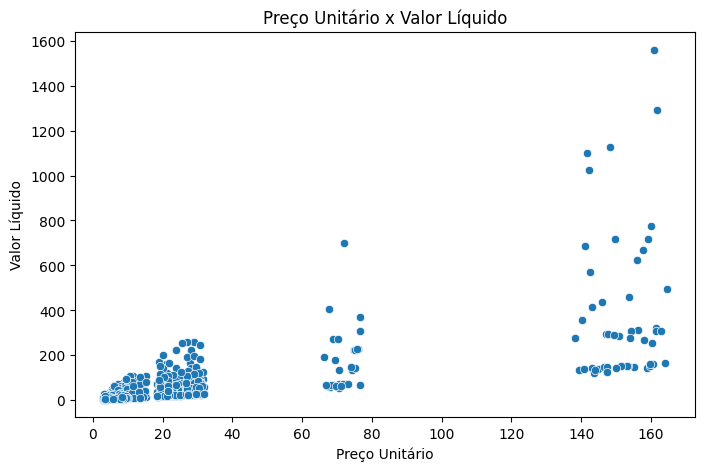

In [54]:
amostra = df.sample(1000, seed=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=amostra["preco_unitario"].to_numpy(),
    y=amostra["valor_liquido"].to_numpy(),
)

plt.title("Preço Unitário x Valor Líquido")
plt.xlabel("Preço Unitário")
plt.ylabel("Valor Líquido")
plt.show()

## 14. Resumo final

Com esse notebook foi possível:

- carregar um dataset real com Polars
- explorar a estrutura dos dados
- converter tipos com expressões (`with_columns`, `pl.col`)
- gerar estatísticas básicas
- agregar dados com `group_by().agg()`
- criar diferentes tipos de gráficos com Matplotlib e Seaborn

### Tabela de equivalência Pandas → Polars

| Pandas | Polars |
|---|---|
| `pd.read_csv` | `pl.read_csv` |
| `df.info()` | `df.schema` / `df.null_count()` |
| `pd.to_datetime(col)` | `pl.col(c).str.to_datetime()` |
| `df[c] = ...` | `df.with_columns(...)` |
| `df.groupby(c)[v].sum()` | `df.group_by(c).agg(pl.col(v).sum())` |
| `s.value_counts()` | `s.value_counts(sort=True)` |
| `df.sample(n, random_state=42)` | `df.sample(n, seed=42)` |
| `df.plot(...)` | não existe → Matplotlib/Seaborn |